<a href="https://colab.research.google.com/github/kiann23-art/New-Project-/blob/main/FinalNotebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Final Notebook

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score, RepeatedKFold
from sklearn.inspection import permutation_importance
from scipy.optimize import differential_evolution

SEED = 42
DATA_PATH = "/content/data.csv"
os.makedirs("figures", exist_ok=True)

##Load and Inspect

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.isna().sum())

(50, 12)
Index(['layer_height', 'wall_thickness', 'infill_density', 'infill_pattern',
       'nozzle_temperature', 'bed_temperature', 'print_speed', 'material',
       'fan_speed', 'roughness', 'tension_strenght', 'elongation'],
      dtype='object')
layer_height          float64
wall_thickness          int64
infill_density          int64
infill_pattern         object
nozzle_temperature      int64
bed_temperature         int64
print_speed             int64
material               object
fan_speed               int64
roughness               int64
tension_strenght        int64
elongation            float64
dtype: object
layer_height          0
wall_thickness        0
infill_density        0
infill_pattern        0
nozzle_temperature    0
bed_temperature       0
print_speed           0
material              0
fan_speed             0
roughness             0
tension_strenght      0
elongation            0
dtype: int64


## Models and Cross-Validation

                   Mean MAE  STD MAE
Gradient Boosting      4.39     1.41
Random Forest          4.91     1.14
Linear Regression      5.14     1.11
Baseline               7.93     1.14


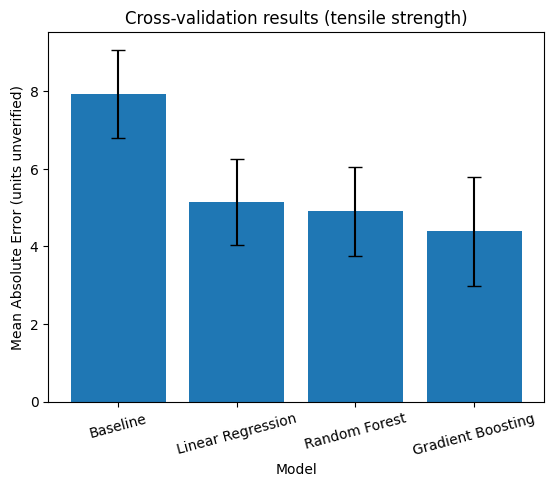

In [3]:
# Column groups, defined once. Section 4 reuses them.
feature_cols = ['layer_height', 'wall_thickness', 'infill_density', 'infill_pattern',
                'nozzle_temperature', 'bed_temperature', 'print_speed', 'material', 'fan_speed']
text_cols = ["infill_pattern", "material"]
num_cols = [c for c in feature_cols if c not in text_cols]

X = df[feature_cols]
y = df["tension_strenght"]  # column name is misspelled in the source data

# Encoder and scaler live inside the pipeline so they are fit on training folds only (no leakage)
prep = ColumnTransformer([
    ("encode_text", OneHotEncoder(handle_unknown="ignore"), text_cols),
    ("scale_nums", StandardScaler(), num_cols),
])

# One splitter shared by every model, so all models are scored on identical folds
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)

models = {
    "Baseline": Pipeline([("prep", prep), ("reg", DummyRegressor(strategy="mean"))]),
    "Linear Regression": Pipeline([("prep", prep), ("reg", LinearRegression())]),
    "Random Forest": Pipeline([("prep", prep), ("reg", RandomForestRegressor(n_estimators=100, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", prep), ("reg", GradientBoostingRegressor(n_estimators=100, random_state=SEED))]),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="neg_mean_absolute_error")
    cv_results[name] = (-scores.mean(), scores.std())  # sklearn returns negative MAE, so flip the sign

cv_results_table = pd.DataFrame(cv_results, index=["Mean MAE", "STD MAE"]).T.round(2).sort_values("Mean MAE")
print(cv_results_table)

names = list(cv_results.keys())
means = [v[0] for v in cv_results.values()]
stds = [v[1] for v in cv_results.values()]

plt.bar(names, means, yerr=stds, capsize=5)
plt.title("Cross-validation results (tensile strength)")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (units unverified)")
plt.xticks(rotation=15)
# save before show(): show() clears the figure, so saving after would write a blank image
plt.savefig("figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Permutation Importance

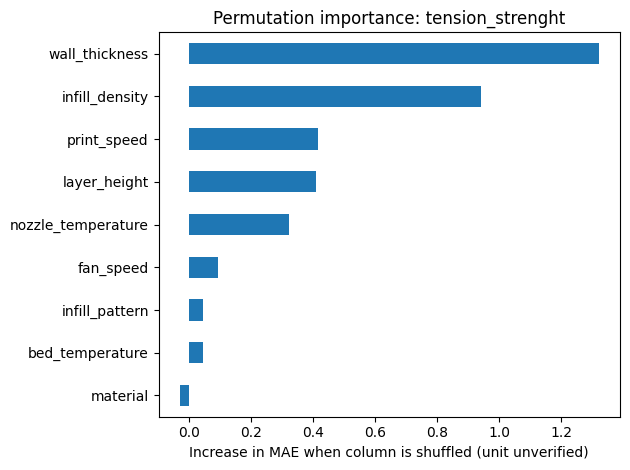

wall_thickness        1.321914
infill_density        0.940310
print_speed           0.415580
layer_height          0.409827
nozzle_temperature    0.322441
fan_speed             0.093595
infill_pattern        0.045720
bed_temperature       0.044544
material             -0.030678
dtype: float64
          min  max  count
material                 
abs       220  250     25
pla       200  220     25


In [4]:
def plot_permutation_importance(df, target_col, unit):
    X = df[feature_cols]
    y = df[target_col]

    # Same encoder and scaler as Section 3, inside the pipeline so they are fit on training rows only
    prep = ColumnTransformer([
        ("encode_text", OneHotEncoder(handle_unknown="ignore"), text_cols),
        ("scale_nums", StandardScaler(), num_cols),
    ])
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

    # Hyperparameters were tuned on tensile strength only; they are untuned for other targets
    model = Pipeline([
        ("prep", prep),
        ("model", RandomForestRegressor(max_depth=6, min_samples_leaf=1, n_estimators=50, random_state=SEED)),
    ])
    model.fit(X_train, y_train)

    # Importance is measured on held-out rows (only 10 here, so bars are noisy)
    result = permutation_importance(model, X_test, y_test,
                                    scoring="neg_mean_absolute_error",
                                    n_repeats=30, random_state=SEED)
    importance = pd.Series(result.importances_mean, index=X.columns).sort_values()

    plt.figure()
    importance.plot(kind="barh")
    plt.title(f"Permutation importance: {target_col}")
    plt.xlabel(f"Increase in MAE when column is shuffled ({unit})")
    plt.tight_layout()
    # save before show(): show() clears the figure
    plt.savefig(f"figures/permutation_importance_{target_col}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return importance

importance = plot_permutation_importance(df, "tension_strenght", "unit unverified")
print(importance.sort_values(ascending=False))

# Nozzle temperature ranges by material: they barely overlap, so the two are confounded
print(df.groupby("material")["nozzle_temperature"].agg(["min", "max", "count"]))

# Predict then Optimize

In [5]:
# ---- Settings ----
PENALTY_WEIGHT = 100   # large enough that any roughness violation outweighs any strength gain
ROUGHNESS_CAP = 165.5  # median roughness in the data; units unverified

# ---- Predict: one model per output, fit on all 50 rows ----
X_opt = df[text_cols + num_cols]

def create_model():
    prep = ColumnTransformer([
        ("encode_text", OneHotEncoder(handle_unknown="ignore"), text_cols),
        ("scale_nums", StandardScaler(), num_cols),
    ])
    return Pipeline([
        ("prep", prep),
        ("model", RandomForestRegressor(max_depth=6, min_samples_leaf=1, n_estimators=50, random_state=SEED)),
    ])

strength_model = create_model()
roughness_model = create_model()  # reuses tensile hyperparameters: untuned and not cross-validated
strength_model.fit(X_opt, df["tension_strenght"])
roughness_model.fit(X_opt, df["roughness"])

# ---- Search space: only values observed in the data ----
# Key order must match decode's x[0] to x[3]
allowed = {col: sorted(df[col].unique().tolist())
           for col in ["layer_height", "wall_thickness", "infill_density", "print_speed"]}

# Bed and fan move together in this data, so search over observed pairs, not independently
pairs_df = df[["bed_temperature", "fan_speed"]].drop_duplicates()
bed_fan_pairs = list(zip(pairs_df["bed_temperature"], pairs_df["fan_speed"]))

# ABS and PLA were printed at different nozzle temperatures, so the nozzle list depends on material
nozzle_by_material = {
    m: sorted(df.loc[df["material"] == m, "nozzle_temperature"].unique().tolist())
    for m in df["material"].unique()
}

base_bounds = [(0, len(values) - 1) for values in allowed.values()]
pair_bound = (0, len(bed_fan_pairs) - 1)

# ---- Decode: the optimizer returns index numbers, not settings ----
def decode_pair(index):
    return bed_fan_pairs[int(round(index))]

def decode(x, nozzle_list):
    layer_height       = allowed["layer_height"][int(round(x[0]))]
    wall_thickness     = allowed["wall_thickness"][int(round(x[1]))]
    infill_density     = allowed["infill_density"][int(round(x[2]))]
    print_speed        = allowed["print_speed"][int(round(x[3]))]
    bed, fan           = decode_pair(x[4])
    nozzle_temperature = nozzle_list[int(round(x[5]))]
    return layer_height, wall_thickness, infill_density, print_speed, bed, fan, nozzle_temperature

def build_row(x, material, infill_pattern, nozzle_list):
    layer_height, wall, infill, speed, bed, fan, nozzle = decode(x, nozzle_list)
    # Start from a real row so every column exists, then overwrite all nine settings
    row = X_opt.iloc[[0]].copy()
    row["material"] = material
    row["infill_pattern"] = infill_pattern
    row["layer_height"] = layer_height
    row["wall_thickness"] = wall
    row["infill_density"] = infill
    row["print_speed"] = speed
    row["bed_temperature"] = bed
    row["fan_speed"] = fan
    row["nozzle_temperature"] = nozzle
    return row

# ---- Optimize: minimize -strength + penalty (negating turns minimizing into maximizing) ----
def cost(x, material, infill_pattern, nozzle_list):
    row = build_row(x, material, infill_pattern, nozzle_list)
    strength = strength_model.predict(row)[0]
    roughness = roughness_model.predict(row)[0]
    violation = max(0, roughness - ROUGHNESS_CAP)  # zero when the cap is respected
    return -strength + PENALTY_WEIGHT * violation

# Categorical choices (material, pattern) are looped over, not searched
results = {}
for material, nozzle_list in nozzle_by_material.items():
    for pattern in ["grid", "honeycomb"]:
        bounds = base_bounds + [pair_bound, (0, len(nozzle_list) - 1)]
        result = differential_evolution(cost, bounds,
                                        args=(material, pattern, nozzle_list), seed=SEED)
        results[(material, pattern)] = (result, decode(result.x, nozzle_list))
        print(material, pattern, round(result.fun, 2), results[(material, pattern)][1])

# ---- Best found vs best observed ----
best_key = min(results, key=lambda k: results[k][0].fun)
best_result = results[best_key][0]
best_row = build_row(best_result.x, best_key[0], best_key[1], nozzle_by_material[best_key[0]])
pred_strength = strength_model.predict(best_row)[0]
pred_roughness = roughness_model.predict(best_row)[0]

print("\nBest search result:", best_key, results[best_key][1])
print("Predicted strength:", round(pred_strength, 2), "| predicted roughness:", round(pred_roughness, 2))
print("Cap respected (penalty is zero):", pred_roughness <= ROUGHNESS_CAP)

print("\nBest observed run:")
print(df.loc[df["tension_strenght"].idxmax(), feature_cols + ["tension_strenght", "roughness"]])

abs grid -32.53 (0.1, 7, 90, 60, 75, 75, 220)
abs honeycomb -31.93 (0.06, 6, 80, 60, 60, 0, 220)
pla grid -33.24 (0.1, 6, 90, 60, 75, 75, 210)
pla honeycomb -31.95 (0.1, 6, 90, 60, 75, 75, 215)

Best search result: ('pla', 'grid') (0.1, 6, 90, 60, 75, 75, 210)
Predicted strength: 33.24 | predicted roughness: 164.84
Cap respected (penalty is zero): True

Best observed run:
layer_height          0.06
wall_thickness           6
infill_density          80
infill_pattern        grid
nozzle_temperature     220
bed_temperature         60
print_speed             60
material               abs
fan_speed                0
tension_strenght        37
roughness               75
Name: 10, dtype: object
